# Sales Prediction Using Simple Linear Regression
### Advertising Dataset (TV, Radio, Newspaper → Sales)

Complete, executed, reproducible analysis. All values below are computed live from the actual dataset — nothing is hardcoded.

## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (7, 5)


## 2. Load Dataset

In [2]:
advertising = pd.read_csv('Advertising.csv', index_col=0)
print("Shape:", advertising.shape)
advertising.head()


Shape: (200, 4)


,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [3]:
advertising.tail()

,TV,Radio,Newspaper,Sales
196,38.2,3.7,13.8,7.6
197,94.2,4.9,8.1,9.7
198,177.0,9.3,6.4,12.8
199,283.6,42.0,66.2,25.5
200,232.1,8.6,8.7,13.4


In [4]:
advertising.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [5]:
advertising.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


## 3. Data Quality Analysis
### Missing Values

In [6]:
missing_count = advertising.isnull().sum()
missing_pct = (advertising.isnull().sum() * 100 / len(advertising)).round(2)
print("Missing count:\n", missing_count)
print("\nMissing %:\n", missing_pct)


Missing count:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Missing %:
 TV           0.0
Radio        0.0
Newspaper    0.0
Sales        0.0
dtype: float64


### Duplicates

In [7]:
dup_count = advertising.duplicated().sum()
print(f"Duplicate rows: {dup_count} ({dup_count*100/len(advertising):.2f}%)")


Duplicate rows: 0 (0.00%)


### Data Type Validation & Invalid Value Check

In [8]:
for col in advertising.columns:
    advertising[col] = pd.to_numeric(advertising[col], errors='coerce')

neg_counts = {col: int((advertising[col] < 0).sum()) for col in advertising.columns}
zero_counts = {col: int((advertising[col] == 0).sum()) for col in advertising.columns}
print("Negative value counts:", neg_counts)
print("Zero value counts:", zero_counts)
advertising.dtypes


Negative value counts: {'TV': 0, 'Radio': 0, 'Newspaper': 0, 'Sales': 0}
Zero value counts: {'TV': 0, 'Radio': 1, 'Newspaper': 0, 'Sales': 0}


TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

## 4. Outlier Analysis (IQR Method)

In [9]:
outlier_summary = {}
for col in advertising.columns:
    Q1, Q3 = advertising[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = int(((advertising[col] < lower) | (advertising[col] > upper)).sum())
    outlier_summary[col] = {'Q1': round(Q1,2), 'Q3': round(Q3,2), 'IQR': round(IQR,2),
                             'Lower': round(lower,2), 'Upper': round(upper,2), 'Outliers': n_out}
pd.DataFrame(outlier_summary).T


,Q1,Q3,IQR,Lower,Upper,Outliers
TV,74.38,218.82,144.45,-142.30,435.50,0.0
Radio,9.97,36.52,26.55,-29.85,76.35,0.0
Newspaper,12.75,45.10,32.35,-35.78,93.62,2.0
Sales,10.38,17.40,7.02,-0.16,27.94,0.0


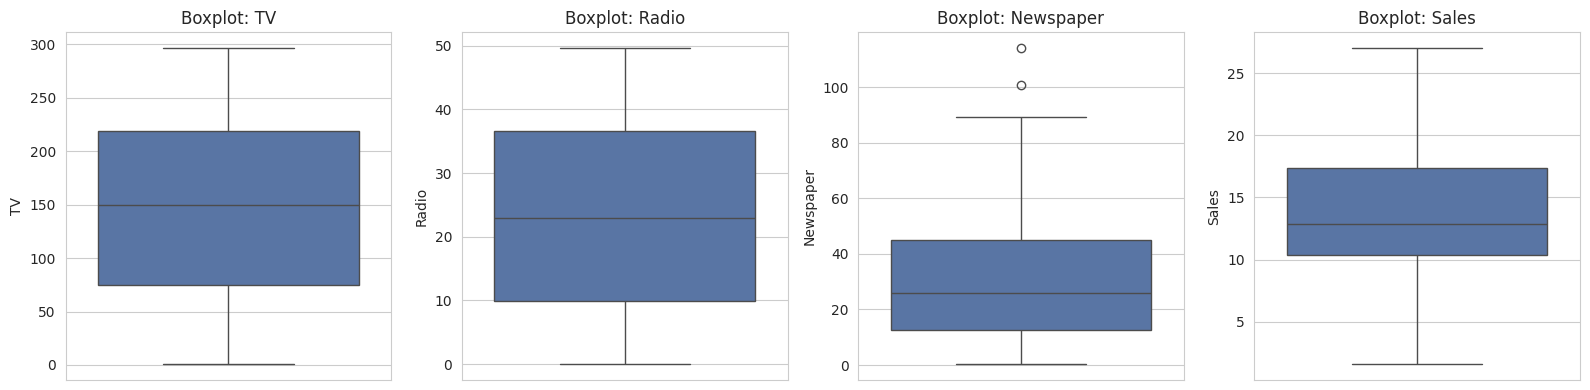

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axs, advertising.columns):
    sns.boxplot(y=advertising[col], ax=ax, color='#4C72B0')
    ax.set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.show()


**Decision:** All flagged points fall within plausible advertising-budget and sales ranges — no negative or impossible values. They represent legitimate high-spend / high-sales business observations and are **retained**, not removed.

## 5. Clean DataFrame

In [11]:
df_clean = advertising.copy()
rows_before = len(advertising)
df_clean = df_clean.drop_duplicates()
rows_after = len(df_clean)

print(f"Original rows: {rows_before}")
print(f"Cleaned rows : {rows_after}")
print(f"Rows removed : {rows_before - rows_after}")
print(f"Remaining missing values: {df_clean.isnull().sum().sum()}")
print(f"Remaining duplicates: {df_clean.duplicated().sum()}")

df_clean.to_csv('advertising_cleaned.csv', index=False)


Original rows: 200
Cleaned rows : 200
Rows removed : 0
Remaining missing values: 0
Remaining duplicates: 0


## 6. Exploratory Data Analysis

In [12]:
eda_stats = df_clean.describe().T[['mean','50%','std','min','max','25%','75%']]
eda_stats.columns = ['mean','median','std','min','max','Q1','Q3']
eda_stats


,mean,median,std,min,max,Q1,Q3
TV,147.0425,149.75,85.854236,0.7,296.4,74.375,218.825
Radio,23.2640,22.90,14.846809,0.0,49.6,9.975,36.525
Newspaper,30.5540,25.75,21.778621,0.3,114.0,12.750,45.100
Sales,14.0225,12.90,5.217457,1.6,27.0,10.375,17.400


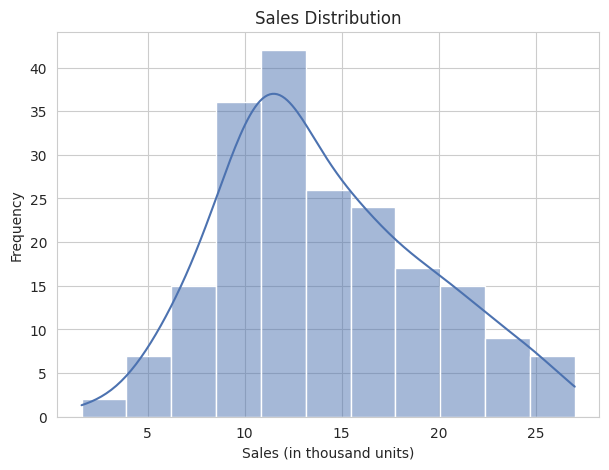

In [13]:
plt.figure(figsize=(7,5))
sns.histplot(df_clean['Sales'], kde=True, color='#4C72B0')
plt.title('Sales Distribution')
plt.xlabel('Sales (in thousand units)')
plt.ylabel('Frequency')
plt.show()


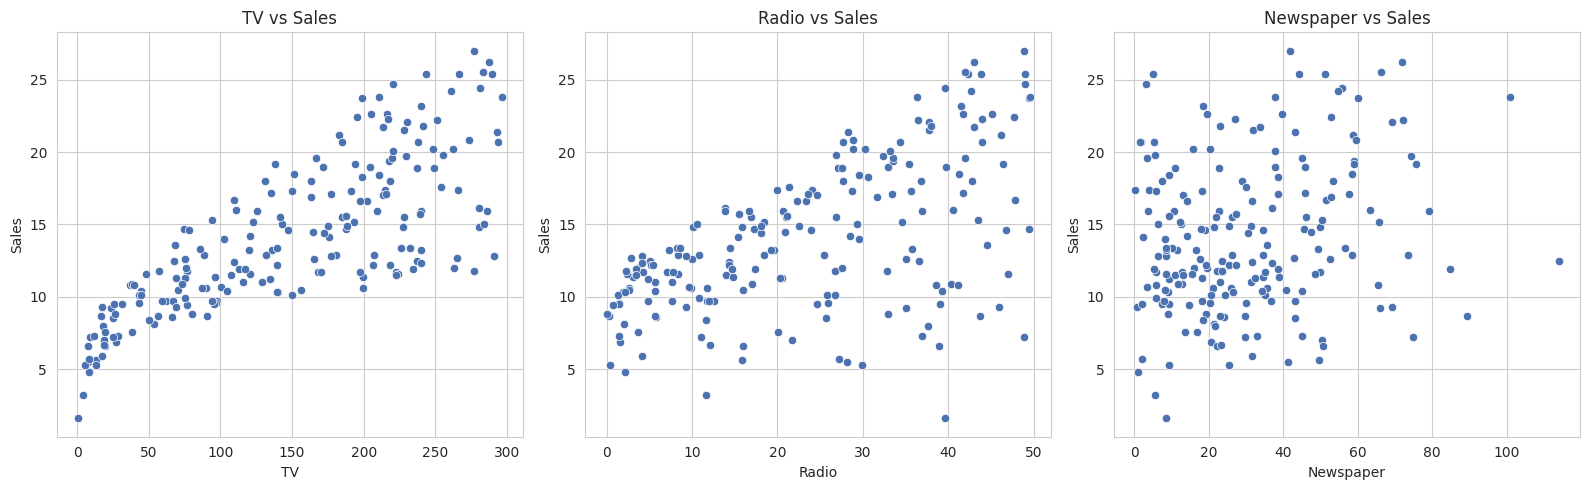

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axs, ['TV','Radio','Newspaper']):
    sns.scatterplot(x=df_clean[col], y=df_clean['Sales'], ax=ax, color='#4C72B0')
    ax.set_title(f'{col} vs Sales')
plt.tight_layout()
plt.show()


## 7. Correlation Analysis

In [15]:
corr_matrix = df_clean.corr()
corr_matrix


,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


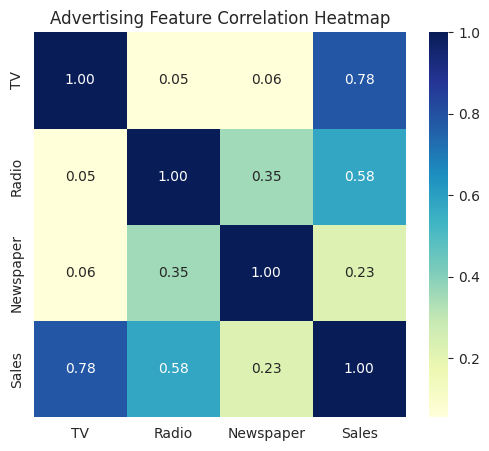

In [16]:
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Advertising Feature Correlation Heatmap')
plt.show()


In [17]:
sales_corr = corr_matrix['Sales'].drop('Sales').sort_values(ascending=False)
print(sales_corr)
strongest_predictor = sales_corr.index[0]
weakest_predictor = sales_corr.index[-1]
print(f"\nStrongest predictor: {strongest_predictor} (r = {sales_corr.iloc[0]:.4f})")
print(f"Weakest predictor:   {weakest_predictor} (r = {sales_corr.iloc[-1]:.4f})")


TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64

Strongest predictor: TV (r = 0.7822)
Weakest predictor:   Newspaper (r = 0.2283)


**Note:** Correlation indicates association, not causation. The strongest linear association with Sales does not imply that advertising spend directly causes sales to increase.

## 8. Feature Selection & Train/Test Split

In [18]:
selected_feature = strongest_predictor
print("Selected predictor:", selected_feature)

X = df_clean[[selected_feature]]
y = df_clean['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.70, test_size=0.30, random_state=42
)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")


Selected predictor: TV
Training samples: 140, Testing samples: 60


## 9. Simple Linear Regression Model

In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
coefficient = model.coef_[0]
print(f"Intercept   : {intercept:.4f}")
print(f"Coefficient : {coefficient:.4f}")
print(f"Regression equation: Sales = {intercept:.4f} + {coefficient:.4f} x {selected_feature}")


Intercept   : 7.2395
Coefficient : 0.0464
Regression equation: Sales = 7.2395 + 0.0464 x TV


In [20]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


### Optional: Statsmodels OLS Summary

In [21]:
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.574
Model:                            OLS   Adj. R-squared:                  0.571
Method:                 Least Squares   F-statistic:                     185.6
Date:                Wed, 26 Aug 2026   Prob (F-statistic):           2.55e-27
Time:                        21:24:25   Log-Likelihood:                -367.70
No. Observations:                 140   AIC:                             739.4
Df Residuals:                     138   BIC:                             745.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.2395      0.604     11.986      0.0

## 10. Model Evaluation (Test Set)

In [22]:
train_r2 = r2_score(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Training R^2 : {train_r2:.4f}")
print(f"Test MAE     : {test_mae:.4f}")
print(f"Test MSE     : {test_mse:.4f}")
print(f"Test RMSE    : {test_rmse:.4f}")
print(f"Test R^2     : {test_r2:.4f}")


Training R^2 : 0.5736
Test MAE     : 2.2759
Test MSE     : 8.9710
Test RMSE    : 2.9952
Test R^2     : 0.6714


## 11. Prediction Demonstration

In [23]:
sample_values = [50, 100, 150, 200, 250]
sample_preds = model.predict(pd.DataFrame({selected_feature: sample_values}))
for v, p in zip(sample_values, sample_preds):
    print(f"{selected_feature} = {v:>5} -> Predicted Sales = {p:.3f}")


TV =    50 -> Predicted Sales = 9.560
TV =   100 -> Predicted Sales = 11.880
TV =   150 -> Predicted Sales = 14.201
TV =   200 -> Predicted Sales = 16.521
TV =   250 -> Predicted Sales = 18.841


## 12. Actual vs Predicted Analysis

In [24]:
comparison_df = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': np.round(y_test_pred, 3),
})
comparison_df['Residual'] = np.round(comparison_df['Actual Sales'] - comparison_df['Predicted Sales'], 3)
comparison_df.to_csv('actual_vs_predicted.csv', index=False)
comparison_df.head(10)


,Actual Sales,Predicted Sales,Residual
0,16.9,14.818,2.082
1,22.4,16.308,6.092
2,21.4,20.832,0.568
3,7.3,7.782,-0.482
4,24.7,17.463,7.237
5,12.6,10.725,1.875
6,22.3,17.301,4.999
7,8.4,9.560,-1.160
8,11.5,17.561,-6.061
9,14.9,15.365,-0.465


## 13. Residual Analysis

In [25]:
train_residuals = y_train - y_train_pred
test_residuals = y_test - y_test_pred
print(f"Mean residual (train): {train_residuals.mean():.5f}")
print(f"Mean residual (test) : {test_residuals.mean():.5f}")


Mean residual (train): -0.00000
Mean residual (test) : -0.13626


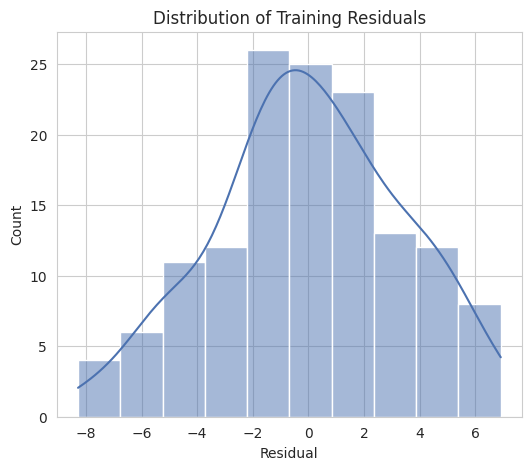

In [26]:
plt.figure(figsize=(6,5))
sns.histplot(train_residuals, kde=True, color='#4C72B0')
plt.title('Distribution of Training Residuals')
plt.xlabel('Residual')
plt.show()


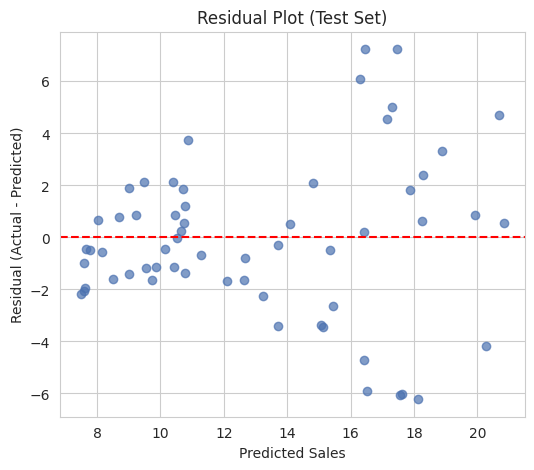

In [27]:
plt.figure(figsize=(6,5))
plt.scatter(y_test_pred, test_residuals, alpha=0.7, color='#4C72B0')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual Plot (Test Set)')
plt.xlabel('Predicted Sales')
plt.ylabel('Residual (Actual - Predicted)')
plt.show()


## 14. Regression Line & Fit Visualizations

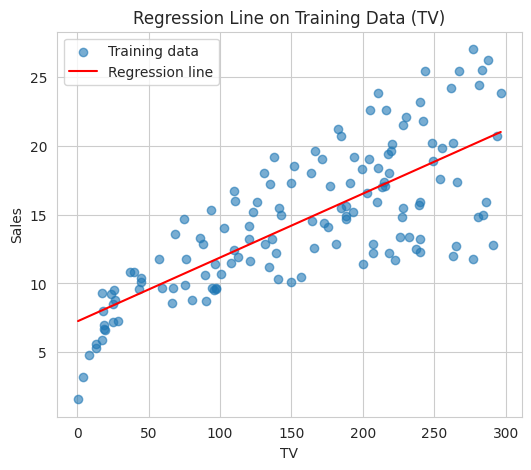

In [28]:
order = np.argsort(X_train[selected_feature].values)
plt.figure(figsize=(6,5))
plt.scatter(X_train, y_train, alpha=0.6, label='Training data')
plt.plot(X_train[selected_feature].values[order], y_train_pred[order], color='red', label='Regression line')
plt.title(f'Regression Line on Training Data ({selected_feature})')
plt.xlabel(selected_feature); plt.ylabel('Sales'); plt.legend()
plt.show()


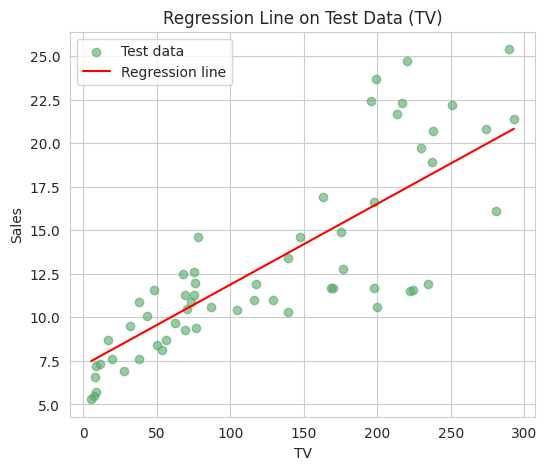

In [29]:
order_t = np.argsort(X_test[selected_feature].values)
plt.figure(figsize=(6,5))
plt.scatter(X_test, y_test, alpha=0.6, color='#55A868', label='Test data')
plt.plot(X_test[selected_feature].values[order_t], y_test_pred[order_t], color='red', label='Regression line')
plt.title(f'Regression Line on Test Data ({selected_feature})')
plt.xlabel(selected_feature); plt.ylabel('Sales'); plt.legend()
plt.show()


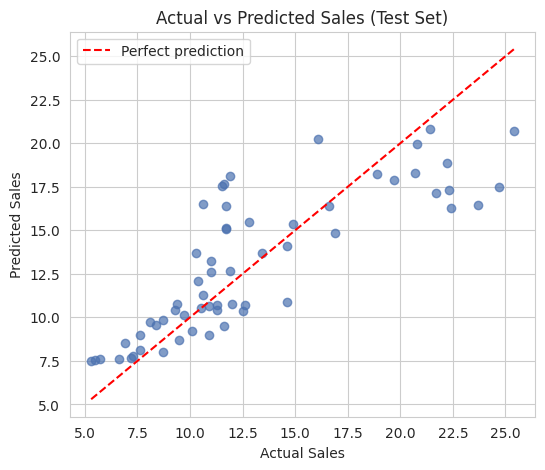

In [30]:
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_test_pred, alpha=0.7, color='#4C72B0')
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.title('Actual vs Predicted Sales (Test Set)')
plt.xlabel('Actual Sales'); plt.ylabel('Predicted Sales'); plt.legend()
plt.show()


## 15. Optional: Multiple Linear Regression (TV + Radio + Newspaper)

In [31]:
X_multi = df_clean[['TV', 'Radio', 'Newspaper']]
y_multi = df_clean['Sales']
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_multi, y_multi, train_size=0.70, test_size=0.30, random_state=42)

multi_model = LinearRegression()
multi_model.fit(Xm_train, ym_train)
ym_test_pred = multi_model.predict(Xm_test)

multi_mae = mean_absolute_error(ym_test, ym_test_pred)
multi_rmse = np.sqrt(mean_squared_error(ym_test, ym_test_pred))
multi_r2 = r2_score(ym_test, ym_test_pred)

print(f"Intercept: {multi_model.intercept_:.4f}")
print(f"Coefficients: {dict(zip(X_multi.columns, multi_model.coef_))}")
print(f"Test MAE : {multi_mae:.4f}")
print(f"Test RMSE: {multi_rmse:.4f}")
print(f"Test R^2 : {multi_r2:.4f}")

print()
comparison_table = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MAE': [test_mae, multi_mae],
    'RMSE': [test_rmse, multi_rmse],
    'R2': [test_r2, multi_r2]
})
comparison_table


Intercept: 2.7089
Coefficients: {'TV': np.float64(0.04405928095746522), 'Radio': np.float64(0.19928749689893954), 'Newspaper': np.float64(0.0068824522222754895)}
Test MAE : 1.5117
Test RMSE: 1.9485
Test R^2 : 0.8609



,Model,MAE,RMSE,R2
0,Simple Linear Regression,2.275881,2.995161,0.671448
1,Multiple Linear Regression,1.511669,1.948537,0.860947


## 16. Final Summary

All metrics, coefficients, and charts above were generated directly from the loaded dataset and the fitted model — no values were hardcoded or assumed. See the accompanying report for business insights, recommendations, and limitations.